# Wolf–elk ODE modeling toolkit

This notebook demonstrates a **reusable numerical ODE class** (`ODESystem`) and a starting **wolf–elk model with farmer and hunter influences**. It is intended for modeling coursework and experimentation, not to predict an actual ecosystem without fitting parameters to field data.

### Mathematical model

Let $E(t)$ be the elk population and $W(t)$ the wolf population, with fixed farmer and hunter influence levels $F$ and $H$:

$$
\begin{aligned}
\frac{dE}{dt} &= r_E E\left(1-\frac{E}{K-\alpha_{FE}F}\right) - aEW - c_{HE}HE,\\
\frac{dW}{dt} &= \eta aEW - d_W W - c_{FW}FW.
\end{aligned}
$$

- **Elk logistic growth:** $r_E E(1-E/K_{\mathrm{eff}})$, with $K_{\mathrm{eff}}=K-\alpha_{FE}F$.
- **Wolf predation on elk:** $-aEW$.
- **Wolf recruitment from predation:** $+\eta aEW$.
- **Natural wolf mortality:** $-d_WW$.
- **Farmer pressure on elk:** farmers reduce elk carrying capacity by $\alpha_{FE}F$.
- **Hunter pressure on elk:** $-c_{HE}HE$.
- **Farmer removal of wolves:** $-c_{FW}FW$.

Here $F$ and $H$ are **external, constant inputs** (farmer/hunter populations or standardized effort), **not evolving populations**. Their coefficients absorb any units/conversion factors. Farmer pressure lowers elk carrying capacity, while farmers also reduce wolves; hunters remove elk in this initial model.

Time units are user-defined but **must be consistent across all rates**. All parameters below are illustrative, **not calibrated** from observational data.

## 1. Setup

Place `ecosystem_ode.py` in the same directory as this notebook. Install dependencies if needed:

```bash
pip install numpy scipy matplotlib notebook
```

Run the cells in order. Every plot function returns `(fig, ax)` for additional Matplotlib customization or saving with `fig.savefig('figure.png', dpi=200)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ecosystem_ode import ODESystem, make_wolf_elk_model, wolf_elk_rhs

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
model = make_wolf_elk_model()
print("Parameters:")
for name, value in model.parameters.items():
    print(f"  {name:5} = {value}")

Parameters:
  r_E   = 0.4
  K     = 1200.0
  alpha_FE = 10.0
  a     = 0.001
  eta   = 0.25
  d_W   = 0.08
  F     = 6.0
  H     = 4.0
  c_HE  = 0.003
  c_FW  = 0.004


## 2. Solve and plot populations over time

Change `initial_populations`, `t_span`, or any parameter to explore a different scenario. The returned solution contains `solution.t` and `solution.y`, with row 0 for elk and row 1 for wolves.

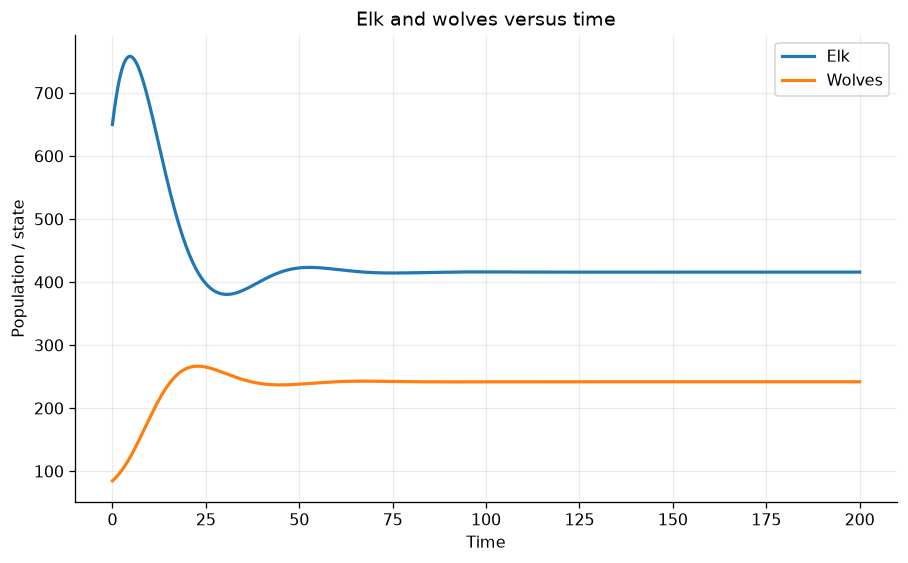

Final populations: elk=416.00, wolves=242.04


In [2]:
initial_populations = [650, 85]  # [elk, wolves]
t_span = (0, 200)
solution = model.solve(initial_populations, t_span, n_points=1201)

fig, ax = model.plot_time_series(solution)
ax.set_title("Elk and wolves versus time")
plt.show()
print(f"Final populations: elk={solution.y[0, -1]:.2f}, wolves={solution.y[1, -1]:.2f}")

## 3. Phase portrait: wolves versus elk

This trajectory shows how the system changes through the $(E,W)$ plane as time advances. The dot marks the initial condition, and arrowheads indicate travel direction.

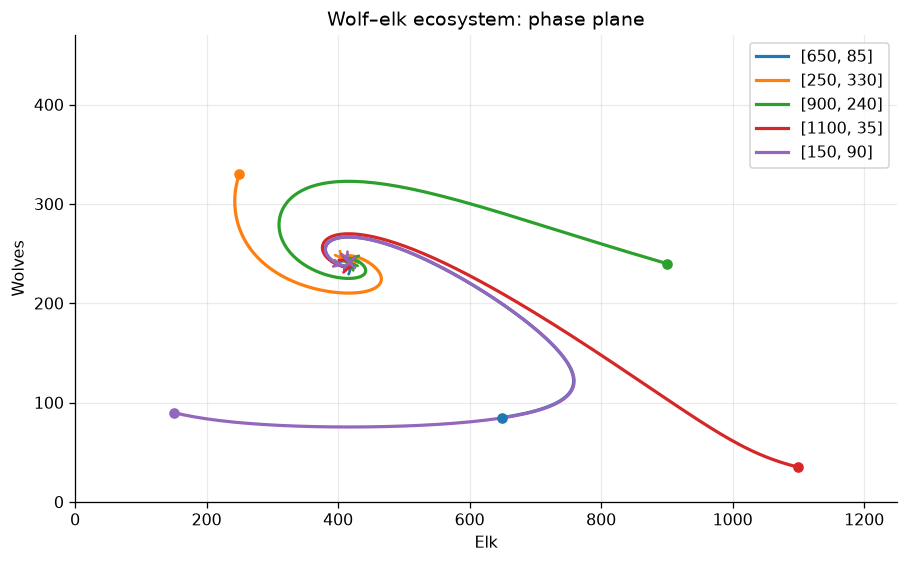

In [3]:
starts = [[650, 85], [250, 330], [900, 240], [1100, 35], [150, 90]]
trajectories = model.solve_many(starts, t_span)
fig, ax = model.plot_phase_plane(trajectories, labels=[str(y0) for y0 in starts], mark_end=True)
ax.set(xlim=(0, 1250), ylim=(0, 470))
plt.show()

## 4. Quiver and stream/“river” fields

- **Quiver:** one arrow at each grid point. By default the arrows are normalized so direction is easier to inspect; their lengths do **not** represent growth speed.
- **Streamplot (river):** continuous flow lines in the phase plane. The colors represent logarithmic vector-field speed, not actual population.

Both plots are best interpreted for a **two-dimensional autonomous system**. Since this example uses constant $F$ and $H$, the field does not depend on time.

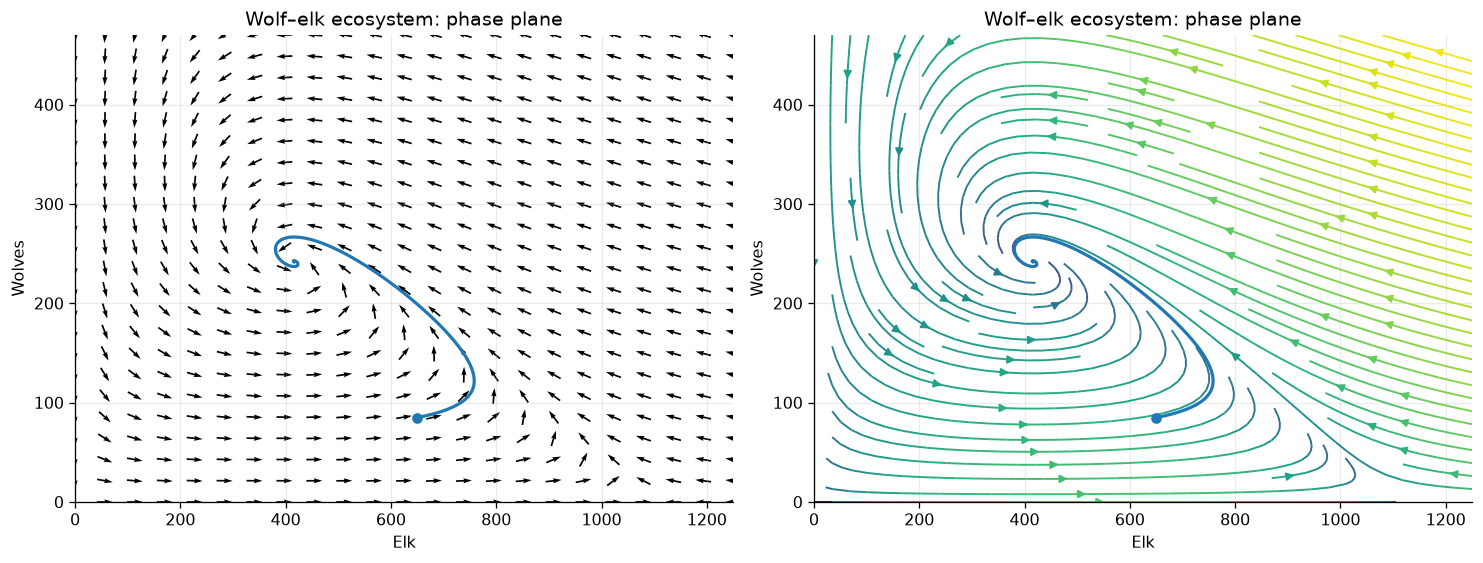

In [4]:
phase_xlim, phase_ylim = (0, 1250), (0, 470)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
model.plot_quiver(phase_xlim, phase_ylim, ax=axes[0], grid=23)
model.plot_streamplot(phase_xlim, phase_ylim, ax=axes[1], grid=61, density=1.25)
for ax in axes:
    model.plot_phase_plane(solution, ax=ax, mark_start=True, direction_arrows=False)
plt.show()

## 5. Nullclines, equilibria, and local stability

An equilibrium has $dE/dt=dW/dt=0$. The **elk-nullcline** and **wolf-nullcline** are curves at which one derivative vanishes. Intersections are candidate fixed points.

For this specific model, define $K_{\mathrm{eff}}=K-\alpha_{FE}F$, $q_H=c_{HE}H$, and $q_W=d_W+c_{FW}F$. The coexistence point, when positive, is

$$E^*=\frac{q_W}{\eta a}, \qquad W^*=\frac{r_E(1-E^*/K_{\mathrm{eff}})-q_H}{a}.$$

A positive coexistence equilibrium exists only if $E^*>0$ and $W^*>0$. We additionally use numerical multi-start root finding and the Jacobian eigenvalues for local stability. Root finding **does not guarantee all roots** are found.

Point (0.00, 0.00) | unstable (saddle-type) | eigenvalues=[ 0.388+0.j -0.104+0.j]
Point (416.00, 242.04) | locally asymptotically stable | eigenvalues=[-0.07298+0.14087j -0.07298-0.14087j]
Point (1105.80, 0.00) | unstable (saddle-type) | eigenvalues=[-0.388  +0.j  0.17245+0.j]


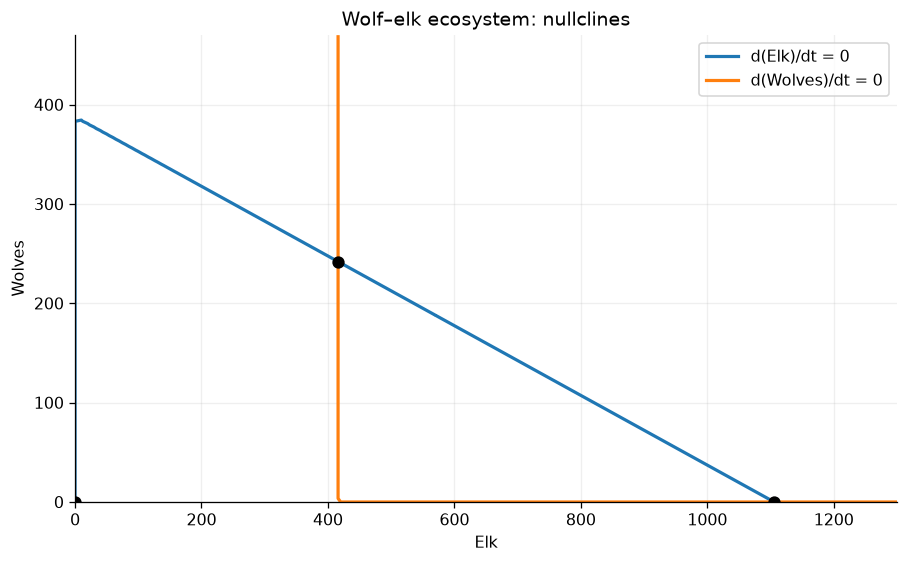

Analytical coexistence candidate: (416.000, 242.035)


In [5]:
fig, ax = model.plot_nullclines((0, 1300), (0, 470), grid=131)
equilibria = model.find_equilibria((0, 1300), (0, 470), starts_per_axis=9)
for equilibrium in equilibria:
    info = model.stability(equilibrium)
    ax.scatter(*equilibrium, color="black", s=45, zorder=6)
    print(f"Point ({equilibrium[0]:.2f}, {equilibrium[1]:.2f}) | "
          f"{info['classification']} | eigenvalues={np.round(info['eigenvalues'], 5)}")
plt.show()

p = model.parameters
elk_star = (p['d_W'] + p['c_FW'] * p['F']) / (p['eta'] * p['a'])
effective_capacity = p['K'] - p['alpha_FE'] * p['F']
wolf_star = (p['r_E'] * (1 - elk_star / effective_capacity)
             - p['c_HE'] * p['H']) / p['a']
print(f"Analytical coexistence candidate: ({elk_star:.3f}, {wolf_star:.3f})")

## 6. Compare farmers, hunters, both, and neither

Each scenario uses the **same initial populations** so differences can be attributed to the input assumptions. The two influence coefficients for farmers affect different state variables ($E$ and $W$).

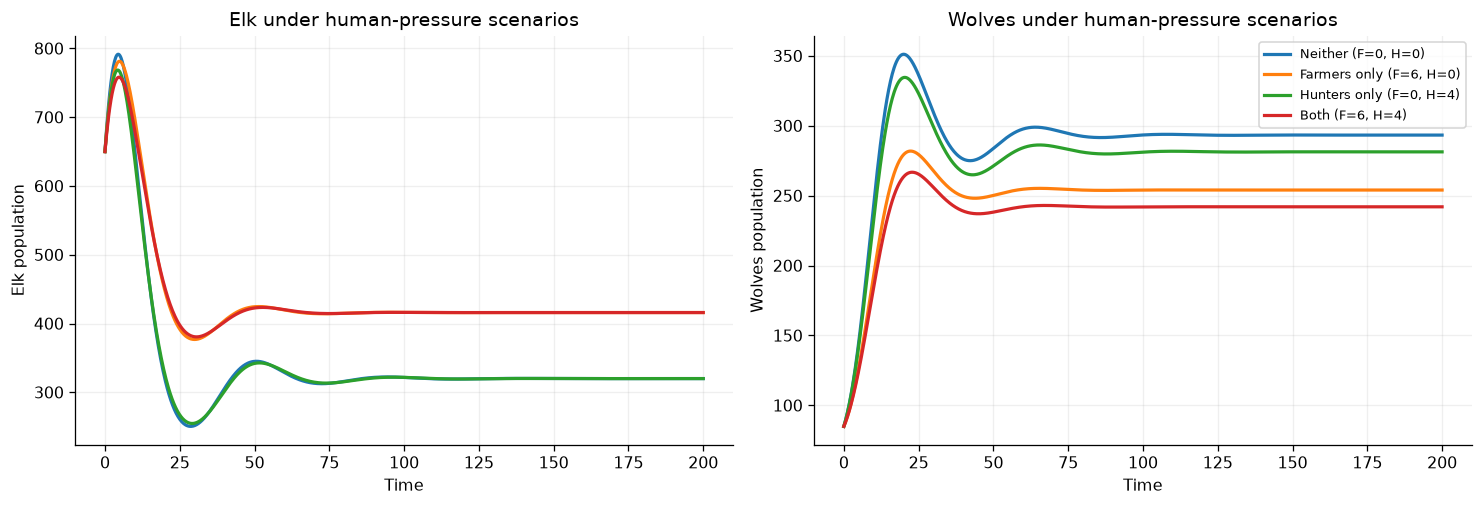

In [6]:
scenarios = {
    "Neither (F=0, H=0)": (0, 0),
    "Farmers only (F=6, H=0)": (6, 0),
    "Hunters only (F=0, H=4)": (0, 4),
    "Both (F=6, H=4)": (6, 4),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (F, H) in scenarios.items():
    trial = model.with_parameters(F=F, H=H).solve(initial_populations, t_span)
    axes[0].plot(trial.t, trial.y[0], lw=2, label=name)
    axes[1].plot(trial.t, trial.y[1], lw=2, label=name)
for i, label in enumerate(["Elk", "Wolves"]):
    axes[i].set(xlabel="Time", ylabel=f"{label} population", title=f"{label} under human-pressure scenarios")
    axes[i].grid(alpha=0.2)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Farmer-pressure parameter sweep

The `parameter_sweep` method solves a new model for every specified parameter value; it does not change the original `model`. The ending population is not necessarily an equilibrium unless the simulation horizon is long enough.

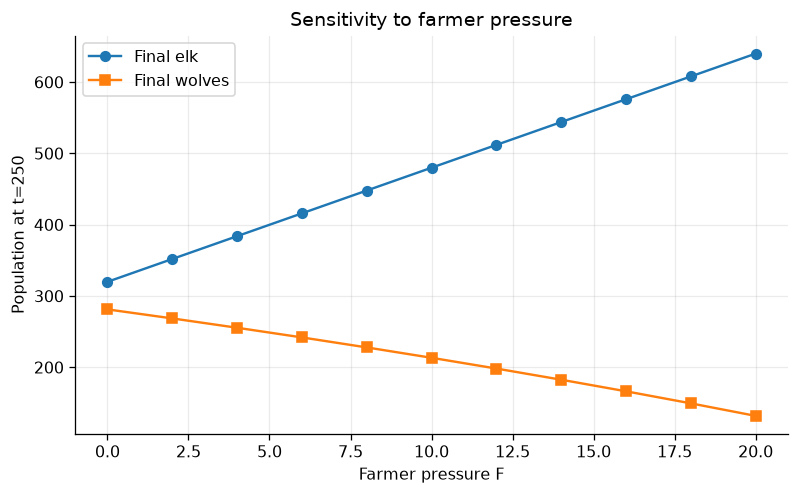

In [7]:
levels = np.linspace(0, 20, 11)
results = model.parameter_sweep("F", levels, initial_populations, (0, 250), n_points=1251)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(levels, [results[float(f)].y[0, -1] for f in levels], "o-", label="Final elk")
ax.plot(levels, [results[float(f)].y[1, -1] for f in levels], "s-", label="Final wolves")
ax.set(xlabel="Farmer pressure F", ylabel="Population at t=250", title="Sensitivity to farmer pressure")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 8. Population 'river' chart (stacked areas)

Sometimes **river graph** means a stacked-area visualization rather than a **streamplot**. The module includes both interpretations: `plot_river(...)` is an alias for `plot_streamplot(...)`, while `plot_population_river(solution)` makes the stacked-area chart below.

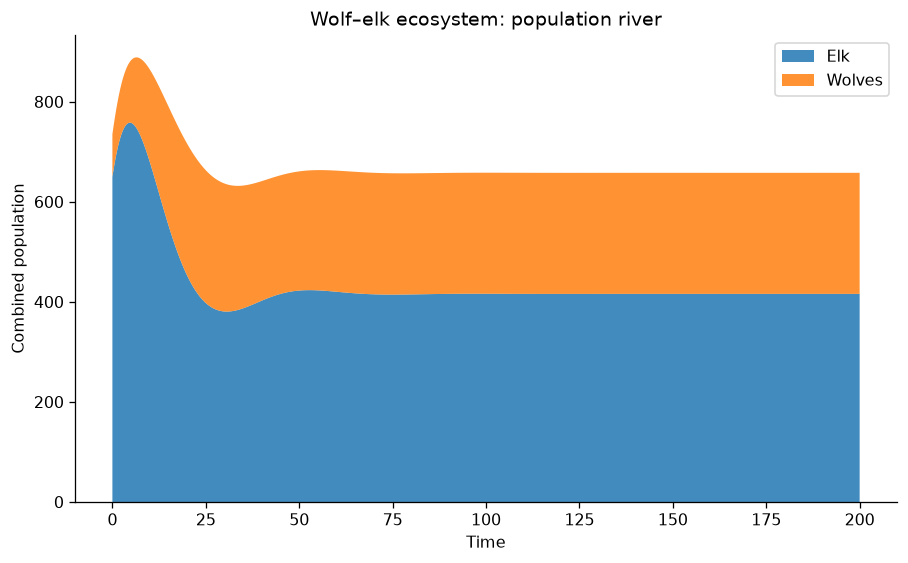

In [8]:
fig, ax = model.plot_population_river(solution)
plt.show()

## 9. Insert a different ODE system

The class is not limited to wolves and elk. Provide any function `my_rhs(t, y, p)` that returns an array of derivatives, along with variable names and a parameter dictionary. The example below is a **two-species competition system** with logistic intraspecific growth and interspecific competition; all the same plot and analysis methods work without modifying the library.

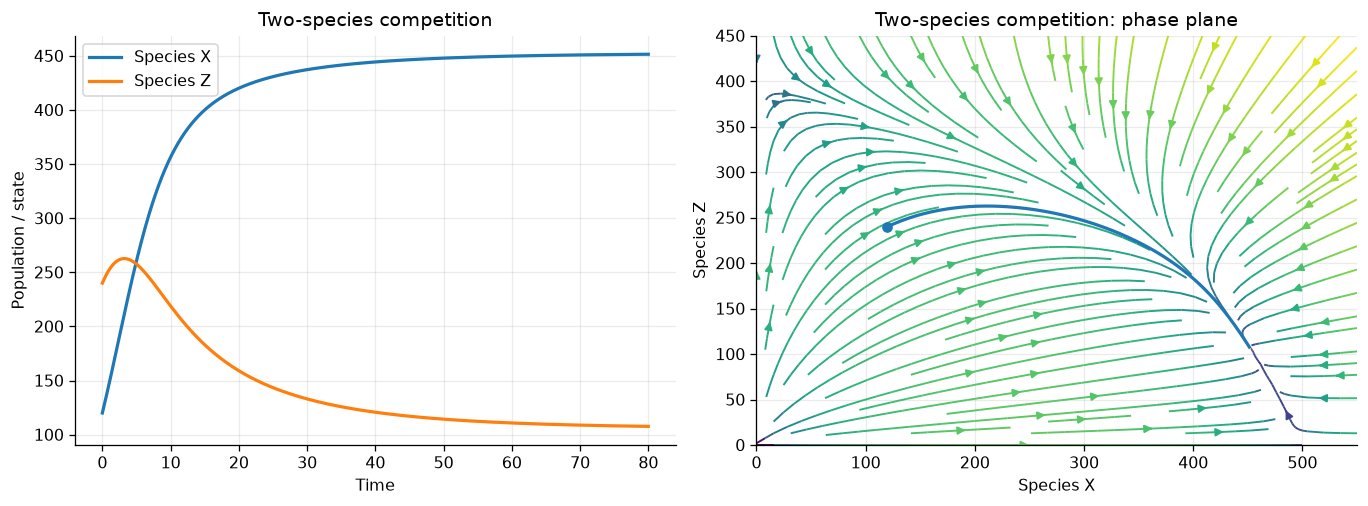

In [9]:
def competition_rhs(t, y, p):
    x, z = y
    dx = p["r_x"] * x * (1 - (x + p["alpha"] * z) / p["K_x"])
    dz = p["r_z"] * z * (1 - (z + p["beta"] * x) / p["K_z"])
    return [dx, dz]

competition = ODESystem(
    rhs=competition_rhs,
    state_names=["Species X", "Species Z"],
    parameters={"r_x": 0.40, "r_z": 0.30, "K_x": 500, "K_z": 400,
                "alpha": 0.45, "beta": 0.65},
    title="Two-species competition",
)
other_sol = competition.solve([120, 240], (0, 80))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
competition.plot_time_series(other_sol, ax=axes[0])
competition.plot_streamplot((0, 550), (0, 450), ax=axes[1])
competition.plot_phase_plane(other_sol, ax=axes[1], direction_arrows=False)
plt.show()

## 10. Optional: time-varying farmer and hunter effort

If human effort varies seasonally, you can make the RHS depend on `t`. Numerical solving still works. **Caution:** a 2D phase portrait of this nonautonomous system is only a trajectory projection; a quiver/streamplot at a specified `t` is just a snapshot, not the full dynamics.

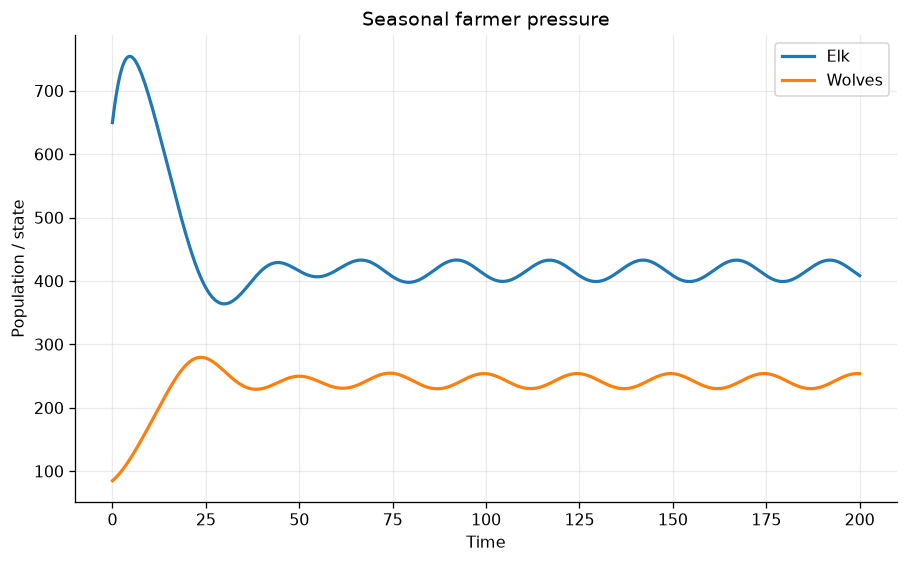

In [10]:
def seasonal_wolf_elk_rhs(t, y, p):
    temporary = dict(p)
    temporary["F"] = p["F"] * (1 + p["amplitude"] * np.sin(2 * np.pi * t / p["period"]))
    return wolf_elk_rhs(t, y, temporary)

seasonal = ODESystem(
    rhs=seasonal_wolf_elk_rhs,
    state_names=["Elk", "Wolves"],
    parameters={**model.parameters, "amplitude": 0.35, "period": 25.0},
    title="Seasonal farmer pressure",
)
seasonal_sol = seasonal.solve(initial_populations, t_span)
fig, ax = seasonal.plot_time_series(seasonal_sol)
plt.show()

## Model interpretation and next steps

**What this model does:** farmer pressure reduces elk carrying capacity, wolves eat elk and reproduce from those encounters, hunters reduce elk, and farmers reduce wolves. The construction makes $E=0$ and $W=0$ invariant boundaries when all rates and initial populations are nonnegative.

**What it does not assume:** farming or hunting effort changes in response to animal populations; spatial structure, age classes, prey switching, disease, or seasonal breeding. The default use of $aEW$ is a **mass-action functional response**; at high elk densities it may be more appropriate to study a saturating response (e.g. Holling type II).

**To make farmers and hunters dynamic populations:** extend the state vector to `[E, W, F, H]` and write four ODEs. The generic solver and time-series plotting already support extra variables; a 2D vector-field plot of a higher-dimensional model must specify `fixed_state` for the other dimensions.

**For a research-level model:** identify plausible units and time scales, fit parameters to data, test model sensitivity, examine alternative functional responses and human-harvest rules, and clearly separate assumptions from empirical claims.